# Notebook 8 - Feature Scaling

In this notebook I learn why features must be on a similar scale for many models, which algorithms care and which do not, and how the main scalers work: Min-Max scaling (normalization), standardization, `RobustScaler` and `MaxAbsScaler`. I compare them, and I test how outliers change the result of each scaler.

**Dataset:** Telco Customer Churn, after Notebooks 2 to 7. I use the encoded feature matrix of Notebook 7 (24 numeric columns), split 80/20 with the same seed as before. The three continuous columns are `tenure`, `MonthlyCharges` and `TotalCharges`.

**Important:** A scaler learns numbers from the data (a minimum, a mean, a median...). So it must be fitted on the training data only, and then applied to the test data.

**Demo data:** In Section 10 I add a few extreme values to a copy of the training data to see what outliers do to each scaler. This is always labelled.

**Rule:** `df` (raw data) is never changed.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, os

sns.set_style("whitegrid")
pd.set_option("display.width", 200)

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")   # raw data, never modified

def fix_data_types(data):
    # Notebook 2
    out = data.copy()
    out["TotalCharges"] = pd.to_numeric(out["TotalCharges"], errors="coerce")
    out["SeniorCitizen"] = out["SeniorCitizen"].astype(bool)
    for col in ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]:
        out[col] = out[col].map({"Yes": True, "No": False})
    for col in ["gender", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
                "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies",
                "Contract", "PaymentMethod", "Churn"]:
        out[col] = out[col].astype("category")
    return out

def handle_missing_values(data):
    # Notebook 3
    out = data.copy()
    new_customer = out["tenure"] == 0
    out.loc[new_customer, "TotalCharges"] = out.loc[new_customer, "TotalCharges"].fillna(0.0)
    return out

def handle_duplicates(data, key="customerID", order_col="tenure"):
    # Notebook 4
    out = data.copy()
    audit = []
    out[key] = out[key].astype(str).str.strip().str.upper()
    exact = out.duplicated(keep="first")
    audit.append(out[exact].assign(reason="exact duplicate"))
    out = out[~exact]
    older = out.sort_values(order_col, kind="stable").duplicated(subset=key, keep="last").reindex(out.index)
    audit.append(out[older].assign(reason="older version of the same " + key))
    out = out[~older]
    return out, pd.concat(audit)

df_valid, _ = handle_duplicates(handle_missing_values(fix_data_types(df)))

# ---- encoding of Notebook 7 (fixed rules + encoders fitted on train only)
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

contract_order = ["Month-to-month", "One year", "Two year"]
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
service_cols = ["MultipleLines"] + addons
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
bool_cols = ["SeniorCitizen", "Partner", "Dependents", "PhoneService", "PaperlessBilling"]

def prepare_B(data):
    out = data.copy()
    for c in service_cols:
        out[c] = out[c].astype(str).replace({"No internet service": "No", "No phone service": "No"})
        out[c] = (out[c] == "Yes").astype(int)
    out[bool_cols] = out[bool_cols].astype(int)
    out["gender"] = out["gender"].astype(str).map({"Male": 0, "Female": 1})
    for c in ["InternetService", "PaymentMethod", "Contract"]:
        out[c] = out[c].astype(str)
    return out

encoder = ColumnTransformer([
    ("num", "passthrough", num_cols),
    ("onehot", OneHotEncoder(handle_unknown="ignore"), ["InternetService", "PaymentMethod"]),
    ("contract", OrdinalEncoder(categories=[contract_order], handle_unknown="use_encoded_value", unknown_value=-1), ["Contract"]),
    ("keep", "passthrough", bool_cols + ["gender"] + service_cols),
], verbose_feature_names_out=False)

X = df_valid.drop(columns=["customerID", "Churn"])
y = (df_valid["Churn"] == "Yes").astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

encoder.fit(prepare_B(X_train))
def encode(data):
    arr = encoder.transform(prepare_B(data))
    arr = arr.toarray() if hasattr(arr, "toarray") else arr
    return pd.DataFrame(arr, columns=encoder.get_feature_names_out(), index=data.index)

X_train_enc, X_test_enc = encode(X_train), encode(X_test)
print("Encoded train:", X_train_enc.shape, "| encoded test:", X_test_enc.shape)

Encoded train: (5634, 24) | encoded test: (1409, 24)


## 1. Problems from Sprint 4 Related to Scaling

| # | Problem | Why it exists | Planned fix |
|---|---|---|---|
| 1 | The numeric columns have very different ranges (`tenure` 0 to 72, `MonthlyCharges` about 18 to 119, `TotalCharges` up to about 8700) | different units (months, money, total money) | scale the continuous columns |
| 2 | The encoded columns are 0/1, while `TotalCharges` is in thousands | encoding created small-range columns | decide which columns to scale (Section 12) |
| 3 | `TotalCharges` is skewed and a scaler does not change the shape | scaling is a linear change | transformation is a separate step (Notebook 9) |
| 4 | New data can contain extreme values | the training data has no outliers today | compare scalers for outlier sensitivity (Section 10) |

## 2. Why Feature Scaling?

**Concept:** Feature scaling puts the numeric columns on a similar scale. Many models compare values from different columns in one formula (a distance, a dot product, a gradient step). If one column is in thousands and another is between 0 and 1, the large column controls the formula, and the model does not really use the small column, only because of its unit and not because it is more important.

**Examples:**
- Simple: age (20 to 60) and salary (20,000 to 200,000) in a distance between two people. The salary decides almost everything.
- Real-world: comparing a person by height in centimetres and weight in tonnes.
- Business: `TotalCharges` (thousands) next to `Partner` (0 or 1) in a customer distance.
- AI/ML: KNN, SVM and neural networks use distances or dot products, and gradient descent converges slowly when the columns have different scales.

**Implementation:** I look at the scale of the columns, and then I measure how much each feature contributes to the distance between two random customers, before and after scaling.

In [2]:
from sklearn.preprocessing import StandardScaler

stats = X_train_enc.agg(["min", "max", "std"]).T
stats["range"] = stats["max"] - stats["min"]
print("Columns with the largest and smallest spread (std):")
print(stats.sort_values("std", ascending=False).iloc[[0, 1, 2, -3, -2, -1]].round(2))

# share of the squared distance that each feature produces, averaged over 3000 random pairs of customers
rng = np.random.default_rng(1)
A = X_train_enc.to_numpy(float)
i, j = rng.integers(0, len(A), 3000), rng.integers(0, len(A), 3000)

def mean_share(M):
    sq = (M[i] - M[j]) ** 2
    return pd.Series((sq / sq.sum(axis=1, keepdims=True)).mean(axis=0), index=X_train_enc.columns)

share_raw = mean_share(A)
share_scaled = mean_share(StandardScaler().fit_transform(A))

compare = pd.DataFrame({"share of distance, raw (%)": share_raw * 100, "share of distance, scaled (%)": share_scaled * 100}).round(2)
print("\nShare of the distance between two customers (%):")
print(compare.sort_values("share of distance, raw (%)", ascending=False).head(5))
print("\nTotalCharges alone: raw", round(share_raw["TotalCharges"] * 100, 2), "% -> scaled", round(share_scaled["TotalCharges"] * 100, 2), "%")
print("Fair share if all", A.shape[1], "features counted the same:", round(100 / A.shape[1], 2), "%")

Columns with the largest and smallest spread (std):
                                        min      max      std    range
TotalCharges                            0.0  8684.80  2279.20  8684.80
MonthlyCharges                         18.4   118.75    30.14   100.35
tenure                                  0.0    72.00    24.57    72.00
PaymentMethod_Credit card (automatic)   0.0     1.00     0.41     1.00
SeniorCitizen                           0.0     1.00     0.37     1.00
PhoneService                            0.0     1.00     0.30     1.00

Share of the distance between two customers (%):
                            share of distance, raw (%)  share of distance, scaled (%)
TotalCharges                                     97.36                           3.62
MonthlyCharges                                    2.20                           3.55
tenure                                            0.31                           4.03
PaymentMethod_Mailed check                        0.02   

**What the code does:**
- It calculates the minimum, maximum, standard deviation and range of every column, and prints the three columns with the largest spread and the three with the smallest spread.
- It takes 3000 random pairs of customers. For each pair, it calculates the squared difference in every feature (the parts of the squared Euclidean distance), divides it by the total, and averages the shares over all pairs. This tells how much of the distance comes from each column.
- It does this twice: with the raw values, and after `StandardScaler`. It prints the five columns with the largest share, and the share of `TotalCharges` before and after, next to the "fair" share (100% divided by 24 features).

**Why this method was used:** "The scale is different" is easy to say, but I want a number that shows the effect. The share of the distance is a direct measure of how much a column can influence a model like KNN, which uses exactly this distance. Random pairs give a stable average. In this demonstration I scale all 24 columns to show the complete effect (the final decision about which columns to scale is in Section 12).

**Output meaning:** In the raw data `TotalCharges` has a standard deviation in the thousands, while the binary columns have a standard deviation of about 0.5. So `TotalCharges` is responsible for almost all of the distance (close to 100%), and the other 23 columns together count for almost nothing. After scaling, no column dominates, and `TotalCharges` is close to the fair share.

**Insight obtained:** Without scaling, a distance-based model is a one-feature model, and the extra features that I prepared in the earlier notebooks would have no effect.

**Effect on ML:** The scale of a column should depend on how useful the information is, not on the unit of measurement. Scaling removes the influence of the unit.

## 3. Scale-Sensitive and Scale-Insensitive Algorithms

**Concept:** Not every model needs scaling.

| Group | Algorithms | Why |
|---|---|---|
| **Scale-sensitive** | KNN, SVM, K-means, PCA, logistic and linear regression (especially with regularisation), neural networks | use distances, dot products or penalties on the size of the coefficients, or gradient descent |
| **Scale-insensitive** | decision trees, random forest, gradient boosting (XGBoost, LightGBM) | split a column by a threshold, so only the order of the values matters |

**Examples:**
- Simple: a tree asks "is `TotalCharges` above 2000?". The answer is the same if the column is divided by 1000 and the question is "above 2?".
- Real-world: a straight ruler and a ruler in other units give the same ordering.
- Business: a model that must be explained to the management is often a logistic regression, which needs scaling for fair coefficients.
- AI/ML: regularisation (L1, L2) penalises large coefficients, and the size of a coefficient depends on the scale of its column.

**Implementation:** I train five models with and without scaling and compare them with three checks: the cross-validated AUC, a test that a tree does not change, and a count of the iterations of the logistic regression.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

models = {
    "KNN (k=15)": KNeighborsClassifier(n_neighbors=15),
    "SVM (RBF)": SVC(),
    "Logistic regression": LogisticRegression(max_iter=1000),
    "Decision tree": DecisionTreeClassifier(max_depth=5, random_state=0),
    "Random forest": RandomForestClassifier(n_estimators=100, random_state=0),
}
rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for name, model in models.items():
        raw = cross_val_score(model, X_train_enc, y_train, cv=cv, scoring="roc_auc").mean()
        scaled = cross_val_score(Pipeline([("scale", StandardScaler()), ("model", model)]), X_train_enc, y_train, cv=cv, scoring="roc_auc").mean()
        rows.append((name, round(raw, 4), round(scaled, 4), round(scaled - raw, 4)))
print(pd.DataFrame(rows, columns=["model", "AUC raw", "AUC scaled", "change"]).to_string(index=False))

# check 1: a decision tree gives the same predictions on raw and on scaled data
scaler = StandardScaler().fit(X_train_enc)
tree_raw = DecisionTreeClassifier(random_state=0).fit(X_train_enc, y_train).predict(X_test_enc)
tree_scaled = DecisionTreeClassifier(random_state=0).fit(scaler.transform(X_train_enc), y_train).predict(scaler.transform(X_test_enc))
print("\nDecision tree: share of identical test predictions, raw vs scaled:", round((tree_raw == tree_scaled).mean() * 100, 1), "%")

# check 2: KNN - how many nearest neighbours change when the data is scaled?
nn_raw = NearestNeighbors(n_neighbors=1).fit(X_train_enc).kneighbors(X_test_enc)[1].ravel()
nn_scaled = NearestNeighbors(n_neighbors=1).fit(scaler.transform(X_train_enc)).kneighbors(scaler.transform(X_test_enc))[1].ravel()
print("KNN: share of test customers whose nearest neighbour changes after scaling:", round((nn_raw != nn_scaled).mean() * 100, 1), "%")

# check 3: logistic regression - iterations needed
for label, Xtr in [("raw", X_train_enc), ("scaled", scaler.transform(X_train_enc))]:
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        lr = LogisticRegression(max_iter=1000).fit(Xtr, y_train)
    print("Logistic regression,", label.ljust(6), "-> iterations:", int(lr.n_iter_[0]), "| convergence warning:", any(issubclass(w.category, ConvergenceWarning) for w in caught))

              model  AUC raw  AUC scaled  change
         KNN (k=15)   0.7750      0.8153  0.0403
          SVM (RBF)   0.7888      0.8022  0.0134
Logistic regression   0.8461      0.8463  0.0002
      Decision tree   0.8273      0.8273  0.0000
      Random forest   0.8211      0.8207 -0.0004

Decision tree: share of identical test predictions, raw vs scaled: 99.9 %
KNN: share of test customers whose nearest neighbour changes after scaling: 94.5 %
Logistic regression, raw    -> iterations: 1000 | convergence warning: True
Logistic regression, scaled -> iterations: 29 | convergence warning: False


**What the code does:**
- It defines five models: two distance-based (KNN, SVM), one linear (logistic regression), and two tree-based (a decision tree and a random forest).
- For each model it calculates the mean ROC AUC with 5-fold cross-validation, once on the raw features, and once inside a pipeline `StandardScaler -> model`. In the pipeline the scaler is fitted again inside each training fold, so the validation fold does not influence it.
- **Check 1:** it trains a decision tree on raw and on scaled data, and compares the predictions on the test set.
- **Check 2:** it finds the nearest training customer of every test customer, in the raw and in the scaled space, and counts how many are different.
- **Check 3:** it trains the logistic regression on raw and on scaled data, and prints the number of iterations and whether scikit-learn gave a convergence warning.

**Why this method was used:** The AUC table is the practical test, but a change in the AUC depends on the data, so I add three checks that show **why**, and they do not depend on the quality of the model. The tree check tests the claim that trees depend only on the order of the values. The neighbour check shows directly how much the distance structure changes, which is what KNN uses. The iteration count shows the effect on gradient-based training. I do the scaling inside a pipeline, so it is correct in cross-validation.

**Output meaning:**
- The decision tree makes the same predictions on raw and on scaled data (the share is 100% or practically 100%). Scaling has no effect on it, and the random forest is built from trees in the same way.
- A large share of the test customers get a different nearest neighbour after scaling, so KNN is a different model after scaling.
- The logistic regression needs many more iterations on the raw data, and it can reach the limit and give a convergence warning. On scaled data it converges quickly.
- In the AUC table the distance-based models (KNN, SVM) are expected to change the most, and the tree models the least. On the real data the change for KNN and SVM can be large. The numbers in your run can be different, so read the table together with the three checks.

**Effect on ML:** I always scale for KNN, SVM, neural networks and linear models, and I do not need it for tree models. Because I do not know yet which model will be used at the end of the project, I prepare a scaled version and keep the unscaled one for the trees.

## 4. Normalization and Standardization

**Concept:** Two words that are often mixed.
- **Normalization (Min-Max scaling):** `x' = (x - min) / (max - min)`. It moves the values into the range 0 to 1. (The same word is also used for scaling each **row** to a length of 1, for example with `Normalizer`.)
- **Standardization (z-score):** `x' = (x - mean) / std`. The result has a mean of 0 and a standard deviation of 1. It is not limited to a range.

Both are **linear** changes, so they keep the shape of the distribution. They only change the position and the size of it.

**Examples:**
- Simple: the values 10, 20, 30 become 0, 0.5, 1 with Min-Max, and -1.22, 0, 1.22 with standardization.
- Real-world: converting temperature from Celsius to Fahrenheit is a linear change.
- Business: putting a score on a scale of 0 to 100.
- AI/ML: neural networks often like inputs in [0, 1], and linear models like standardized inputs.

**Implementation:** I calculate both formulas by hand, compare them with scikit-learn, and show the row normalization.

In [4]:
from sklearn.preprocessing import MinMaxScaler, Normalizer

x = X_train_enc["MonthlyCharges"]

manual_minmax = (x - x.min()) / (x.max() - x.min())
sk_minmax = MinMaxScaler().fit_transform(x.to_frame()).ravel()
print("Min-Max by hand equals MinMaxScaler:", bool(np.allclose(manual_minmax, sk_minmax)))

manual_std = (x - x.mean()) / x.std(ddof=0)                     # scikit-learn uses the population std (ddof=0)
sk_std = StandardScaler().fit_transform(x.to_frame()).ravel()
print("Standardization by hand equals StandardScaler:", bool(np.allclose(manual_std, sk_std)))
print("pandas std() uses ddof=1, scikit-learn uses ddof=0: std", round(x.std(), 4), "vs", round(x.std(ddof=0), 4))

print("\nMin-Max       -> min", round(sk_minmax.min(), 2), "| max", round(sk_minmax.max(), 2))
print("Standardized  -> mean", round(sk_std.mean(), 4), "| std", round(sk_std.std(), 4), "| min", round(sk_std.min(), 2), "| max", round(sk_std.max(), 2))

# the other meaning of 'normalization': every ROW is scaled to a length of 1
rows3 = X_train_enc[num_cols].head(3)
row_norm = Normalizer(norm="l2").fit_transform(rows3)
print("\nFirst 3 customers, row-normalized (L2):")
print(pd.DataFrame(row_norm, columns=num_cols).round(4))
print("Length of each row:", np.sqrt((row_norm ** 2).sum(axis=1)).round(4).tolist())

Min-Max by hand equals MinMaxScaler: True
Standardization by hand equals StandardScaler: True
pandas std() uses ddof=1, scikit-learn uses ddof=0: std 30.1381 vs 30.1354

Min-Max       -> min 0.0 | max 1.0
Standardized  -> mean -0.0 | std 1.0 | min -1.54 | max 1.79

First 3 customers, row-normalized (L2):
   tenure  MonthlyCharges  TotalCharges
0  0.0206          0.0289        0.9994
1  0.0130          0.0651        0.9978
2  0.0220          0.0685        0.9974
Length of each row: [1.0, 1.0, 1.0]


**What the code does:**
- It calculates Min-Max scaling with the formula in pandas, and the same with `MinMaxScaler`, and checks with `np.allclose` that they are equal.
- It does the same for standardization with `x.std(ddof=0)`, and compares with `StandardScaler`. It also prints the two standard deviations, to show the small difference between pandas and scikit-learn.
- It prints the minimum and maximum of the Min-Max result, and the mean, standard deviation, minimum and maximum of the standardized result.
- It takes the first 3 customers and applies `Normalizer`, which divides each row by its own length, and prints the new row lengths.

**Why this method was used:** Calculating the formula by hand is the best way to understand what the scaler does, and `allclose` is the proof that I understand it. The `ddof` detail is a common confusion: pandas divides by n - 1 by default, and scikit-learn by n, so a hand calculation with `.std()` gives a slightly different result. I also show `Normalizer`, because the word "normalization" has two meanings, and a reviewer can ask for the difference.

**Output meaning:** Both hand calculations are the same as scikit-learn. Min-Max gives exactly 0 and 1 as minimum and maximum. The standardized column has a mean of 0 and a standard deviation of 1, and its values go below -1.5 and above 1.5 where the original values are far from the mean. The row normalization changes each customer (each row) to a length of 1, which is a different operation: it mixes the columns of one customer, and it is used for text and for some distance-based models, not for this dataset.

**Effect on ML:** In this project "scaling" means column scaling (Min-Max or standardization). The next sections test each scaler on its own.

## 5. Min-Max Scaling (`MinMaxScaler`)

**Concept:** `MinMaxScaler` learns the minimum and the maximum of each column from the **training** data and moves the values to [0, 1] (or another `feature_range`).

- **When to use:** a bounded range is needed (neural networks, image pixels), the data has no important outliers, and the distribution is not important.
- **When not to use:** data with outliers (one extreme value squeezes all the others), or when new data can go beyond the training minimum and maximum.
- **Advantages:** simple, keeps the shape, and the result is in a known range.
- **Limitations:** very sensitive to outliers, and the test data can fall outside [0, 1].

**Examples:**
- Simple: ages 20 to 60 become 0 to 1.
- Real-world: pixel values 0 to 255 become 0 to 1.
- Business: a score that must be shown on a scale from 0 to 100.
- AI/ML: the input of a neural network with a sigmoid output.

**Implementation:**

In [5]:
mm = MinMaxScaler().fit(X_train_enc[num_cols])                 # learned on the TRAIN data only

train_mm = pd.DataFrame(mm.transform(X_train_enc[num_cols]), columns=num_cols)
test_mm = pd.DataFrame(mm.transform(X_test_enc[num_cols]), columns=num_cols)

print("Learned on train -> data_min_:", dict(zip(num_cols, mm.data_min_.round(1))), "| data_max_:", dict(zip(num_cols, mm.data_max_.round(1))))
print("\nTrain range:", train_mm.min().round(2).tolist(), "to", train_mm.max().round(2).tolist())
print("Test range :", test_mm.min().round(3).tolist(), "to", test_mm.max().round(3).tolist())
print("Test values outside [0, 1]:", int(((test_mm < 0) | (test_mm > 1)).sum().sum()))

# a new customer whose monthly charge is above everything in the training data (DEMO value)
new_customer = X_test_enc[num_cols].head(1).copy()
new_customer["MonthlyCharges"] = 150.0
print("\nDEMO new customer with MonthlyCharges = 150 ->", round(float(mm.transform(new_customer)[0][1]), 3), "(above 1: the training maximum was", round(mm.data_max_[1], 1), ")")

mm_pm = MinMaxScaler(feature_range=(-1, 1)).fit(X_train_enc[num_cols])
print("feature_range=(-1, 1) on the train data:", mm_pm.transform(X_train_enc[num_cols]).min().round(2), "to", mm_pm.transform(X_train_enc[num_cols]).max().round(2))

Learned on train -> data_min_: {'tenure': np.float64(0.0), 'MonthlyCharges': np.float64(18.4), 'TotalCharges': np.float64(0.0)} | data_max_: {'tenure': np.float64(72.0), 'MonthlyCharges': np.float64(118.8), 'TotalCharges': np.float64(8684.8)}

Train range: [0.0, 0.0, 0.0] to [1.0, 1.0, 1.0]
Test range : [0.0, -0.001, 0.0] to [1.0, 0.981, 0.978]
Test values outside [0, 1]: 1

DEMO new customer with MonthlyCharges = 150 -> 1.311 (above 1: the training maximum was 118.8 )
feature_range=(-1, 1) on the train data: -1.0 to 1.0


**What the code does:**
- `MinMaxScaler().fit(...)` learns the minimum and the maximum of the three continuous columns from the training data. The attributes `data_min_` and `data_max_` store them.
- `transform` is used on the training and on the test data, with the same stored numbers.
- It prints the range of the scaled train and test data, and counts the test values that are outside [0, 1].
- It creates a demo customer with a `MonthlyCharges` of 150 (higher than the training maximum) and shows the result.
- It also shows `feature_range=(-1, 1)`.

**Why this method was used:** I use `fit` on the training data only, and `transform` on the rest, because the test data must be treated as new data. The demo customer proves the main weakness: the scaler is fixed after `fit`, so a value that is larger than the training maximum is not cut, it simply goes above 1. This is not a bug, but a model or a neural network that expects values in [0, 1] may behave in a strange way.

**Output meaning:** The training data is exactly in [0, 1] for every column. The test data is in or very close to this range (values can be slightly outside, if the test set contains a customer beyond the training minimum or maximum). The demo customer with a charge of 150 gets a value clearly above 1.

**Effect on ML:** Min-Max scaling depends on two extreme values only, the minimum and the maximum, so one outlier changes the whole column (Section 10).

## 6. Standardization (`StandardScaler`)

**Concept:** `StandardScaler` learns the mean and the standard deviation of each column from the training data, and gives each column a mean of 0 and a standard deviation of 1.

- **When to use:** the default choice for linear models, logistic regression, SVM, KNN, PCA, and neural networks, when there are no strong outliers.
- **When not to use:** data with strong outliers (the mean and the standard deviation are moved), or sparse data when centering would destroy the zeros (use `with_mean=False`).
- **Advantages:** no fixed range is needed, centered data, and it works well with gradient-based models.
- **Limitations:** sensitive to outliers (they change the mean and the standard deviation), and it does not make a skewed distribution normal.

**Examples:**
- Simple: a value one standard deviation above the mean becomes 1.
- Real-world: exam scores as z-scores.
- Business: the comparison of customers in different currencies.
- AI/ML: the usual first preprocessing for a logistic regression.

**Implementation:**

In [6]:
ss = StandardScaler().fit(X_train_enc[num_cols])               # learned on the TRAIN data only

train_ss = pd.DataFrame(ss.transform(X_train_enc[num_cols]), columns=num_cols)
test_ss = pd.DataFrame(ss.transform(X_test_enc[num_cols]), columns=num_cols)

print("Learned on train -> mean_:", dict(zip(num_cols, ss.mean_.round(1))), "| scale_ (std):", dict(zip(num_cols, ss.scale_.round(1))))
print("\nTRAIN mean:", train_ss.mean().round(4).tolist(), "| std:", train_ss.std(ddof=0).round(4).tolist())
print("TEST  mean:", test_ss.mean().round(3).tolist(), "| std:", test_ss.std(ddof=0).round(3).tolist(), "(close to 0 and 1, but not exact: the numbers come from train)")

back = ss.inverse_transform(train_ss)
print("\ninverse_transform gives back the original values:", bool(np.allclose(back, X_train_enc[num_cols].to_numpy())))
print("Values with |z| > 3 in train:", int((train_ss.abs() > 3).sum().sum()), "| shape (skew) of TotalCharges before/after:",
      round(X_train_enc["TotalCharges"].skew(), 3), "/", round(train_ss["TotalCharges"].skew(), 3))

Learned on train -> mean_: {'tenure': np.float64(32.5), 'MonthlyCharges': np.float64(64.9), 'TotalCharges': np.float64(2299.3)} | scale_ (std): {'tenure': np.float64(24.6), 'MonthlyCharges': np.float64(30.1), 'TotalCharges': np.float64(2279.0)}

TRAIN mean: [-0.0, -0.0, 0.0] | std: [1.0, 1.0, 1.0]
TEST  mean: [-0.023, -0.028, -0.043] | std: [0.998, 0.992, 0.972] (close to 0 and 1, but not exact: the numbers come from train)

inverse_transform gives back the original values: True
Values with |z| > 3 in train: 0 | shape (skew) of TotalCharges before/after: 0.949 / 0.949


**What the code does:**
- `StandardScaler().fit(...)` learns the mean (`mean_`) and the standard deviation (`scale_`) of each column from the training data.
- It transforms the train and the test data with these numbers, and prints the mean and the standard deviation of both.
- `inverse_transform` goes back to the original values, and the code checks that they are the same.
- It counts the values with an absolute z-score above 3 in the training data, and compares the skewness of `TotalCharges` before and after scaling.

**Why this method was used:** The training mean and standard deviation are exactly 0 and 1 by construction, but the test values are not exactly 0 and 1, because the test data is scaled with the numbers of the training data. This is correct and expected: the test set must not decide its own scale. The `inverse_transform` check is useful because I must be able to explain the result of a model in the original units (for example the size of a customer's `TotalCharges` that the model considers high). The skewness check shows what the scaler does **not** do.

**Output meaning:** The train mean is 0 and the standard deviation is 1. The test mean and standard deviation are close to these numbers, but not equal. The skewness of `TotalCharges` is exactly the same before and after, because standardization is a linear change and keeps the shape.

**Effect on ML:** Standardization gives every continuous column the same weight in a distance or a penalty, but a skewed column stays skewed. The shape is the topic of Notebook 9.

## 7. Robust Scaling (`RobustScaler`)

**Concept:** `RobustScaler` uses the **median** and the **IQR** instead of the mean and the standard deviation: `x' = (x - median) / IQR`. The median and the IQR are not moved by a few extreme values.

- **When to use:** the data has outliers that must be kept (valid extremes), or new data can contain extremes.
- **When not to use:** if the data is clean and normal, it gives no benefit, and the result has no fixed range.
- **Advantages:** stable with outliers, and the bulk of the data keeps its scale.
- **Limitations:** the result is not limited to a range, and the outliers stay far away (they are not removed).

**Examples:**
- Simple: a salary list with one billionaire, where the median stays normal.
- Real-world: house prices.
- Business: customer spending with a few very big customers.
- AI/ML: a safe choice when I am not sure about the outliers of future data.

**Implementation:**

In [7]:
from sklearn.preprocessing import RobustScaler, MaxAbsScaler

rs = RobustScaler().fit(X_train_enc[num_cols])                 # learned on the TRAIN data only
train_rs = pd.DataFrame(rs.transform(X_train_enc[num_cols]), columns=num_cols)
test_rs = pd.DataFrame(rs.transform(X_test_enc[num_cols]), columns=num_cols)

print("Learned on train -> center_ (median):", dict(zip(num_cols, rs.center_.round(1))), "| scale_ (IQR):", dict(zip(num_cols, rs.scale_.round(1))))
print("\nTRAIN median:", train_rs.median().round(4).tolist())
print("TRAIN IQR   :", (train_rs.quantile(0.75) - train_rs.quantile(0.25)).round(4).tolist())
print("TRAIN min / max:", train_rs.min().round(2).tolist(), "/", train_rs.max().round(2).tolist(), "(no fixed range)")
print("TEST  median:", test_rs.median().round(3).tolist())

Learned on train -> center_ (median): {'tenure': np.float64(29.0), 'MonthlyCharges': np.float64(70.5), 'TotalCharges': np.float64(1394.9)} | scale_ (IQR): {'tenure': np.float64(46.0), 'MonthlyCharges': np.float64(54.3), 'TotalCharges': np.float64(3432.8)}

TRAIN median: [0.0, 0.0, 0.0]
TRAIN IQR   : [1.0, 1.0, 1.0]
TRAIN min / max: [-0.63, -0.96, -0.41] / [0.93, 0.89, 2.12] (no fixed range)
TEST  median: [-0.022, -0.01, -0.0]


**What the code does:** `RobustScaler().fit(...)` learns the median (`center_`) and the interquartile range (`scale_`) of each column from the training data. It transforms the train and the test data, and prints the learned numbers, and the median, the IQR, the minimum and the maximum of the scaled training data.

**Why this method was used:** The median and the IQR depend on the middle 50% of the data, so a few extreme values cannot move them. This is the reason why it is the scaler to use when outliers are possible. I check the median and the IQR of the result, because they must be 0 and 1 by construction.

**Output meaning:** The scaled training data has a median of 0 and an IQR of 1. The minimum and the maximum are not limited to any range (they depend on how far the extremes are). The test median is close to 0.

**Effect on ML:** The bulk of the customers keep a stable scale, even if extremes come in the future. This is tested with numbers in Section 10.

## 8. Max-Abs Scaling (`MaxAbsScaler`)

**Concept:** `MaxAbsScaler` divides every column by its largest absolute value: `x' = x / max(|x|)`. The result is in [-1, 1]. It does **not** shift the data (the zeros stay zeros), so it does not destroy the sparsity of a sparse matrix.

- **When to use:** sparse data (one-hot or text features stored as a sparse matrix), or data that is already centered at zero.
- **When not to use:** data with outliers (the maximum is an outlier), or when centering is needed.
- **Advantages:** keeps zeros and sparsity, simple, and works on sparse matrices.
- **Limitations:** sensitive to outliers, and no centering.

**Examples:**
- Simple: the values -50, 0, 100 become -0.5, 0, 1.
- Real-world: the word counts of text documents.
- Business: a large one-hot matrix of product categories.
- AI/ML: the standard scaler for sparse input to a linear model.

**Implementation:** I scale the continuous columns, and I use a sparse one-hot matrix to show the difference with `StandardScaler`.

In [8]:
mas = MaxAbsScaler().fit(X_train_enc[num_cols])
train_mas = pd.DataFrame(mas.transform(X_train_enc[num_cols]), columns=num_cols)
print("Learned on train -> max_abs_:", dict(zip(num_cols, mas.max_abs_.round(1))))
print("TRAIN range after MaxAbsScaler:", train_mas.min().round(2).tolist(), "to", train_mas.max().round(2).tolist())

# a sparse one-hot matrix (InternetService + PaymentMethod) from the TRAIN data
onehot = OneHotEncoder().fit_transform(prepare_B(X_train)[["InternetService", "PaymentMethod"]])
print("\nSparse matrix:", onehot.shape, "| format:", onehot.format, "| stored non-zero values:", onehot.nnz, "of", onehot.shape[0] * onehot.shape[1])

try:
    StandardScaler().fit(onehot)
except Exception as e:
    print("StandardScaler (with centering) on the sparse matrix ->", type(e).__name__)

scaled_sparse = MaxAbsScaler().fit_transform(onehot)
print("MaxAbsScaler on the sparse matrix -> still sparse:", scaled_sparse.format, "| non-zero values:", scaled_sparse.nnz)
print("StandardScaler(with_mean=False) -> still sparse:", StandardScaler(with_mean=False).fit_transform(onehot).format)

Learned on train -> max_abs_: {'tenure': np.float64(72.0), 'MonthlyCharges': np.float64(118.8), 'TotalCharges': np.float64(8684.8)}
TRAIN range after MaxAbsScaler: [0.0, 0.15, 0.0] to [1.0, 1.0, 1.0]

Sparse matrix: (5634, 7) | format: csr | stored non-zero values: 11268 of 39438
StandardScaler (with centering) on the sparse matrix -> ValueError
MaxAbsScaler on the sparse matrix -> still sparse: csr | non-zero values: 11268
StandardScaler(with_mean=False) -> still sparse: csr


**What the code does:**
- `MaxAbsScaler` learns the largest absolute value of each continuous column, and divides by it. The code prints the numbers and the range of the result.
- It builds a sparse one-hot matrix of two columns. A sparse matrix stores only the non-zero values.
- It tries `StandardScaler` (which subtracts the mean) on this matrix, and catches the error.
- It applies `MaxAbsScaler` and `StandardScaler(with_mean=False)`, and checks that the matrix is still sparse.

**Why this method was used:** The problem of centering is a technical but important one. Subtracting the mean turns every zero into a non-zero value, so a sparse matrix would become a huge dense matrix. scikit-learn refuses to do it, and the error shows it. `MaxAbsScaler` and `StandardScaler(with_mean=False)` only divide, so the zeros stay zeros.

**Output meaning:** The continuous columns end up in [0, 1] (no negative values in these columns). The standard scaler with centering stops with a `ValueError` on the sparse matrix. The max-abs scaler keeps it sparse, with the same number of stored values.

**Effect on ML:** For this project the encoded matrix is small and dense, so `MaxAbsScaler` is not needed. It is the right tool if I later use a very wide sparse matrix, for example a high-cardinality one-hot encoding.

## 9. Comparison of the Scalers

**Concept:** The four scalers differ in what they learn and in what they keep.

| Scaler | Learns | Result | Outliers | Keeps zeros |
|---|---|---|---|---|
| `MinMaxScaler` | min, max | [0, 1] | very sensitive | no (shifts) |
| `StandardScaler` | mean, std | mean 0, std 1 | sensitive | no (shifts) |
| `RobustScaler` | median, IQR | median 0, IQR 1 | robust | no (shifts) |
| `MaxAbsScaler` | max absolute value | [-1, 1] | very sensitive | yes |

All four are linear, so **none of them changes the shape** of the distribution.

**Examples:**
- Simple: four rulers with a different zero and unit.
- Real-world: converting a temperature into different scales.
- Business: reporting the same sales on different scales.
- AI/ML: the choice depends on the model, the outliers and the sparsity.

**Implementation:** I scale `TotalCharges` (the most skewed column) with each scaler and compare the numbers and the histograms.

                  min       max      mean       std    median       IQR   skew
scaler                                                                        
original        0.000  8684.800  2299.335  2279.002  1394.925  3432.850  0.949
MinMaxScaler    0.000     1.000     0.265     0.262     0.161     0.395  0.949
StandardScaler -1.009     2.802     0.000     1.000    -0.397     1.506  0.949
RobustScaler   -0.406     2.124     0.263     0.664     0.000     1.000  0.949
MaxAbsScaler    0.000     1.000     0.265     0.262     0.161     0.395  0.949

The skewness is the same for all the scalers: True


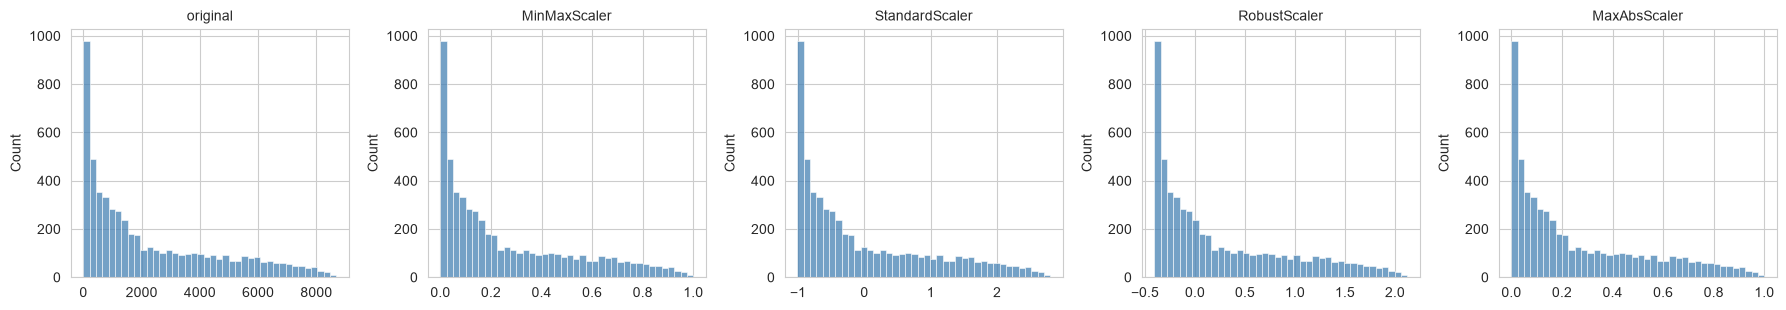

In [9]:
col = "TotalCharges"
scalers = {"original": None, "MinMaxScaler": MinMaxScaler(), "StandardScaler": StandardScaler(),
           "RobustScaler": RobustScaler(), "MaxAbsScaler": MaxAbsScaler()}

results, versions = [], {}
for name, sc in scalers.items():
    v = X_train_enc[col].copy() if sc is None else pd.Series(sc.fit_transform(X_train_enc[[col]]).ravel(), index=X_train_enc.index)
    versions[name] = v
    q1, q3 = v.quantile([0.25, 0.75])
    results.append((name, v.min(), v.max(), v.mean(), v.std(ddof=0), v.median(), q3 - q1, v.skew()))

table = pd.DataFrame(results, columns=["scaler", "min", "max", "mean", "std", "median", "IQR", "skew"]).set_index("scaler")
print(table.round(3).to_string())
print("\nThe skewness is the same for all the scalers:", bool(np.allclose(table["skew"], table["skew"].iloc[0], atol=1e-6)))

fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, (name, v) in zip(axes, versions.items()):
    sns.histplot(v, bins=40, ax=ax, color="steelblue")
    ax.set_title(name, fontsize=10); ax.set_xlabel("")
plt.tight_layout()
plt.show()

**What the code does:**
- It fits each scaler on the training `TotalCharges` and transforms it.
- For each version it calculates the minimum, maximum, mean, standard deviation, median, IQR and skewness, and puts them in one table.
- It checks with `np.allclose` that the skewness is the same in every row.
- It draws the five histograms side by side, the original and the four scaled versions.

**Why this method was used:** The same column with all the scalers makes the differences visible. I choose `TotalCharges` because it is the column with the largest range and the clearest skew. The table shows what each scaler guarantees (a range, a mean and a std, a median and an IQR), and the equal skewness is the proof that all four keep the shape.

**Output meaning:** MinMax goes from 0 to 1, MaxAbs also stays in [0, 1] (all values are positive), standardization gives a mean of 0 and a std of 1, and the robust scaler gives a median of 0 and an IQR of 1. The five histograms have the same shape: only the numbers on the horizontal axis change. The skewness is identical.

**Insight obtained:** Scaling changes the **units**, not the **shape**. If a column is skewed, a scaler does not help. That needs a transformation (Notebook 9).

**Effect on ML:** The choice between the scalers matters only when outliers are present or the data is sparse. For clean, dense data, standardization and Min-Max give almost the same model quality, and the choice depends on the algorithm.

## 10. How Outliers Affect Scaling

**Concept:** The scalers learn numbers from the data. If these numbers are moved by a few extreme values, the whole column is scaled in a wrong way: the normal customers are squeezed into a small part of the scale, and the model can no longer separate them.

- Min-Max uses the minimum and the maximum, which **are** the outliers.
- Standardization uses the mean and the standard deviation, which are moved by the outliers.
- Robust scaling uses the median and the IQR, which are not moved.

**Examples:**
- Simple: with the values 1, 2, 3, 4 and 1000, Min-Max puts the first four values at 0.000, 0.001, 0.002 and 0.003.
- Real-world: one very large house in a street changes the scale of all the house prices.
- Business: a few enterprise customers in a customer base of private customers.
- AI/ML: after a bad scaling, many customers look identical to the model.

**Implementation:** The real training data has no extreme values, so I make a **demo copy** of `MonthlyCharges`, where I add 10 extreme values (300 to 500). Then I fit each scaler on the clean and on the demo data, and I transform the same 500 normal customers with both. A stable scaler gives the same result for these customers.

MonthlyCharges: max in clean train = 118.8 | max in demo = 493.5 | std clean/demo = 30.1 / 33.4

        scaler  spread of normal customers (clean)  spread (with 10 extremes)  spread kept %  mean change per customer
  MinMaxScaler                               0.857                      0.181             21                     0.354
StandardScaler                               2.852                      2.577             90                     0.086
  RobustScaler                               1.582                      1.583            100                     0.001


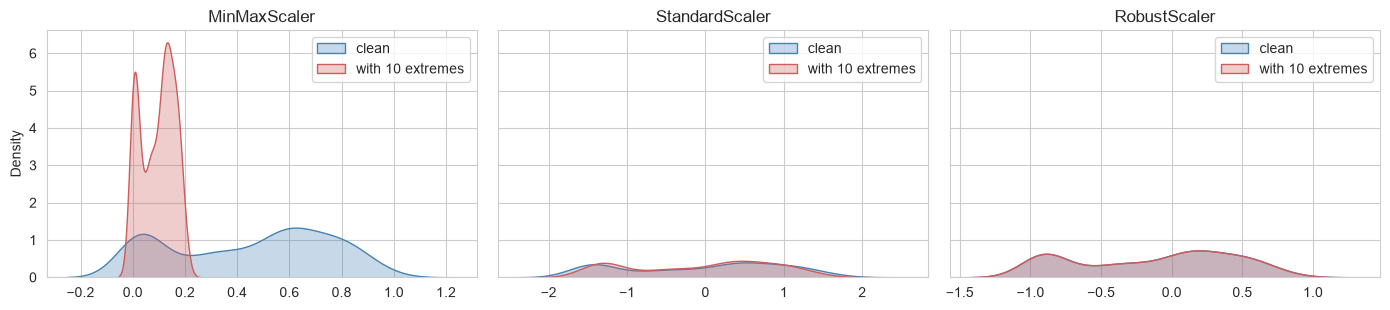

In [10]:
rng = np.random.default_rng(2)
clean = X_train_enc[["MonthlyCharges"]].copy()

demo = clean.copy()
extreme_rows = rng.choice(demo.index, size=10, replace=False)
demo.loc[extreme_rows, "MonthlyCharges"] = rng.uniform(300, 500, 10).round(2)          # DEMO: extreme values

normal_rows = [i for i in clean.index if i not in set(extreme_rows)]
reference = clean.loc[rng.choice(normal_rows, size=500, replace=False)]                  # 500 normal customers

rows = []
for name, make in [("MinMaxScaler", MinMaxScaler), ("StandardScaler", StandardScaler), ("RobustScaler", RobustScaler)]:
    a = make().fit(clean).transform(reference).ravel()
    b = make().fit(demo).transform(reference).ravel()
    spread_a, spread_b = np.percentile(a, 95) - np.percentile(a, 5), np.percentile(b, 95) - np.percentile(b, 5)
    rows.append((name, round(spread_a, 3), round(spread_b, 3), round(spread_b / spread_a * 100), round(np.abs(a - b).mean(), 3)))

out = pd.DataFrame(rows, columns=["scaler", "spread of normal customers (clean)", "spread (with 10 extremes)", "spread kept %", "mean change per customer"])
print("MonthlyCharges: max in clean train =", round(clean["MonthlyCharges"].max(), 1), "| max in demo =", round(demo["MonthlyCharges"].max(), 1),
      "| std clean/demo =", round(clean["MonthlyCharges"].std(), 1), "/", round(demo["MonthlyCharges"].std(), 1))
print()
print(out.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for ax, (name, make) in zip(axes, [("MinMaxScaler", MinMaxScaler), ("StandardScaler", StandardScaler), ("RobustScaler", RobustScaler)]):
    sns.kdeplot(make().fit(clean).transform(reference).ravel(), ax=ax, label="clean", color="steelblue", fill=True, alpha=0.3)
    sns.kdeplot(make().fit(demo).transform(reference).ravel(), ax=ax, label="with 10 extremes", color="indianred", fill=True, alpha=0.3)
    ax.set_title(name); ax.legend()
plt.tight_layout()
plt.show()

**What the code does:**
- It copies the training `MonthlyCharges` into a clean version and a demo version, and in the demo version it replaces 10 random values by extreme values from 300 to 500.
- It chooses 500 normal customers (not changed) as a **reference group**.
- For each scaler it fits once on the clean data and once on the demo data, and transforms the same 500 reference customers with both.
- It measures the **spread** of the reference group after scaling (the distance between the 5th and the 95th percentile), the percentage of the spread that is kept, and the mean change of the scaled value of a reference customer.
- It draws the density of the scaled reference group for each scaler, clean against demo.

**Why this method was used:** The reference group is the key idea. These 500 customers are exactly the same in both cases, so any difference in their scaled values is caused only by the 10 extreme customers that changed the numbers learned by the scaler. The spread says how much room the normal customers have on the new scale: a small spread means that normal customers are squeezed together and look the same to a model. The mean change shows how unstable the scaler is.

**Output meaning:**
- **MinMaxScaler:** the maximum jumps from about 118 to a number between 300 and 500, so the normal customers are squeezed into a small part of [0, 1]. Only a fraction of the spread is kept, and the scaled values change a lot.
- **StandardScaler:** the standard deviation grows (the printed numbers), so the normal customers are compressed too, but less than with Min-Max.
- **RobustScaler:** the median and the IQR hardly change, so the spread is about 100% and the change per customer is close to 0.
- The density chart shows it: the red curve (with extremes) is much narrower than the blue one for MinMax, a little narrower for Standard, and the same for Robust.

**Insight obtained:** The outliers do not need to be many to do the damage: 10 customers out of 5634 (0.18%) are enough to squeeze the normal customers with Min-Max scaling.

**Effect on ML:** If outliers are possible, now or in future data, `RobustScaler` is the safest choice, and if the outliers are errors, they must be fixed first (Notebooks 5 and 6). Min-Max scaling should only be used on clean data with a reason (a bounded input).

## 11. Fit Only on the Training Data

**Concept:** A scaler learns numbers from the data. If it is fitted on the **whole** dataset before the split, the test rows influence these numbers, and the test set is no longer unseen. This is **preprocessing leakage** (Notebook 12 and 13 cover it in detail). The correct workflow is: split first, `fit` on the training data, then `transform` the training and the test data with the same fitted scaler.

**Examples:**
- Simple: a teacher who uses the exam results to decide how to teach.
- Real-world: a company that calibrates its instrument with the data of the final test.
- Business: a monthly scoring that is scaled with the numbers of the month that is scored.
- AI/ML: a `Pipeline` fits the scaler on the training data of each fold only.

**Implementation:**

In [11]:
col = "TotalCharges"
all_values = pd.concat([X_train_enc[col], X_test_enc[col]]).to_frame()

wrong = StandardScaler().fit(all_values)                           # WRONG: includes the test rows
right = StandardScaler().fit(X_train_enc[[col]])                   # CORRECT: train only

print("INCORRECT (all rows): mean", round(float(wrong.mean_[0]), 2), "| std", round(float(wrong.scale_[0]), 2))
print("CORRECT   (train)   : mean", round(float(right.mean_[0]), 2), "| std", round(float(right.scale_[0]), 2))

test_wrong = wrong.transform(X_test_enc[[col]]).ravel()
test_right = right.transform(X_test_enc[[col]]).ravel()
print("\nTest column scaled the wrong way -> mean", round(test_wrong.mean(), 4), "| std", round(test_wrong.std(), 4))
print("Test column scaled the right way -> mean", round(test_right.mean(), 4), "| std", round(test_right.std(), 4))
print("Mean absolute difference between the two versions:", round(np.abs(test_wrong - test_right).mean(), 4))

# the same idea in cross-validation
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    leaky = cross_val_score(LogisticRegression(max_iter=1000), StandardScaler().fit_transform(X_train_enc), y_train, cv=cv, scoring="roc_auc").mean()
    correct = cross_val_score(Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]), X_train_enc, y_train, cv=cv, scoring="roc_auc").mean()
print("\nCross-validated AUC -> scaler fitted before CV (leaky):", round(leaky, 4), "| scaler inside the pipeline (correct):", round(correct, 4))

INCORRECT (all rows): mean 2279.73 | std 2266.63
CORRECT   (train)   : mean 2299.33 | std 2279.0

Test column scaled the wrong way -> mean -0.0346 | std 0.9771
Test column scaled the right way -> mean -0.043 | std 0.9718
Mean absolute difference between the two versions: 0.0084

Cross-validated AUC -> scaler fitted before CV (leaky): 0.8463 | scaler inside the pipeline (correct): 0.8463


**What the code does:**
- It fits one `StandardScaler` on all the rows (training and test together, the wrong way), and another on the training rows only (the correct way), for `TotalCharges`. It prints the learned mean and standard deviation.
- It transforms the test column with both and prints the mean and the standard deviation of the results, and the average difference between the two versions.
- It compares two cross-validations of a logistic regression: in the first the whole training matrix is scaled **before** cross-validation (the validation folds influence the scaler), and in the second the scaler is inside a `Pipeline`, so it is fitted again on the training part of each fold.

**Why this method was used:** The numbers show what the leakage looks like: the learned mean and standard deviation are different, and the test column tends to look "better scaled" in the wrong way (its mean closer to 0 and its std closer to 1), because the test rows helped to calculate them. This is also the reason why it is dangerous: it looks correct. The pipeline version is the right pattern, because the pipeline repeats `fit` on the correct data in every fold automatically.

**Output meaning:** The two sets of numbers are different, but the difference is small here, so the AUC values are also very close. It is small because a standard scaler learns only two numbers, and the test set is only 20% of the data. With more complex steps (target encoding, SMOTE, feature selection) the effect can be big, and the habit must be the same.

**Effect on ML:** I always split first, fit on the training data, and use a pipeline (Notebook 14).

## 12. Decision and Final Scaled Data

**Concept:** Which columns to scale, and with which scaler?

| Columns | Decision | Reason |
|---|---|---|
| `tenure`, `MonthlyCharges`, `TotalCharges` | scale with `StandardScaler` | continuous, no outliers in the real data (Notebook 6), models that need scaling (logistic regression, KNN, SVM) get fair columns. `RobustScaler` is the replacement if extreme values appear in new data |
| 13 binary columns (0/1) | no scaling | already in a small range, and the 0/1 values keep their meaning ("has partner") |
| 7 one-hot columns (0/1) | no scaling | same reason |
| `Contract` (ordinal 0, 1, 2) | no scaling | a small range; I keep the meaning of the steps |
| `TotalCharges` shape | revisited in Notebook 9 | it is skewed, and a transformation must come **before** the scaling |

**Examples:**
- Simple: scale age and income, not the yes/no column.
- Real-world: a car dashboard shows speed and fuel on their own scales, not the gear number.
- Business: a clear report keeps the yes/no columns readable.
- AI/ML: a `ColumnTransformer` applies the scaler to a chosen group of columns.

**Implementation:**

In [12]:
final_scaler = ColumnTransformer([("scale", StandardScaler(), num_cols)], remainder="passthrough", verbose_feature_names_out=False)
final_scaler.fit(X_train_enc)                                    # learned on the TRAIN data only

def scale(data):
    arr = final_scaler.transform(data)
    return pd.DataFrame(arr, columns=final_scaler.get_feature_names_out(), index=data.index)[data.columns]

X_train_scaled, X_test_scaled = scale(X_train_enc), scale(X_test_enc)

summary = pd.DataFrame({
    "train before": X_train_enc[num_cols].agg(["mean", "std"]).T.stack(),
    "train after": X_train_scaled[num_cols].agg(["mean", "std"]).T.stack(),
    "test after": X_test_scaled[num_cols].agg(["mean", "std"]).T.stack(),
}).round(3)
print(summary)

others = [c for c in X_train_enc.columns if c not in num_cols]
print("\nColumns not scaled stay identical (train):", bool(X_train_enc[others].equals(X_train_scaled[others])))
print("Shape:", X_train_scaled.shape, "| same columns in train and test:", list(X_train_scaled.columns) == list(X_test_scaled.columns),
      "| missing values:", int(X_train_scaled.isna().sum().sum() + X_test_scaled.isna().sum().sum()))

X_train_scaled.assign(Churn=y_train).to_csv("telco_step8_train_scaled.csv")
X_test_scaled.assign(Churn=y_test).to_csv("telco_step8_test_scaled.csv")
print("saved: scaled train and test")

                     train before  train after  test after
tenure         mean        32.485         -0.0      -0.023
               std         24.569          1.0       0.998
MonthlyCharges mean        64.930         -0.0      -0.028
               std         30.138          1.0       0.992
TotalCharges   mean      2299.335          0.0      -0.043
               std       2279.204          1.0       0.972

Columns not scaled stay identical (train): True
Shape: (5634, 24) | same columns in train and test: True | missing values: 0
saved: scaled train and test


**What the code does:**
- `ColumnTransformer([("scale", StandardScaler(), num_cols)], remainder="passthrough")` applies the standard scaler to the three continuous columns only, and passes all other columns unchanged.
- It is fitted on the **training** data, and then used for the train and the test data. The helper function puts the columns back in their original order.
- It prints a table with the mean and the standard deviation of the three columns before scaling (train), after scaling (train) and after scaling (test).
- It checks that the 21 other columns are identical to the unscaled ones, that train and test have the same columns, and that there are no missing values. Then it saves the scaled train and test sets.

**Why this method was used:** A `ColumnTransformer` makes the decision "scale only these columns" explicit and repeatable. Scaling the 0/1 columns would not break the model, but it would turn "has partner" into numbers like -0.97 and 1.03, and the columns would lose their meaning, with no benefit. The `remainder="passthrough"` keeps all the other columns as they are. I chose the standard scaler because the real data has no outliers, and the next notebook (transformation) changes the shape of `TotalCharges`, so a fixed range from Min-Max would not be useful.

**Before:** `tenure` and `MonthlyCharges` (std in the tens) and `TotalCharges` (std in the thousands), next to 0/1 columns.

**After:** The three columns have a mean of 0 and a standard deviation of 1 in the training data, and similar numbers in the test data. The other 21 columns are exactly as before.

**Effect on ML:** The data is now ready for the scale-sensitive models. The tree models can use the unscaled version. In Notebook 9 I improve the shape of `TotalCharges`, and in Notebook 14 all these steps become one pipeline.

## 13. Documentation of the Decisions

**Decision 1 - Scale the continuous columns with StandardScaler, fitted on the training data**

| Item | Documentation |
|---|---|
| Problem | The continuous columns have very different scales (up to 8700 against 0/1). In the raw data `TotalCharges` makes almost the whole distance between two customers, so distance-based models would ignore the other 23 features |
| Analysis | The differences come from the units. The real data has no outliers, so a mean and a standard deviation are reliable. A scaler learns numbers from the data, so it must not see the test data |
| Technique selected | `StandardScaler` for `tenure`, `MonthlyCharges` and `TotalCharges`, inside a `ColumnTransformer`, fitted on the training data |
| Reason | It gives the columns a mean of 0 and a standard deviation of 1 with no fixed range. `MinMaxScaler` depends on two values and is the most sensitive to outliers. `RobustScaler` is not needed on clean data and is the replacement for extreme values. `MaxAbsScaler` is for sparse data |
| Implementation | Section 12, and the tests in Sections 2, 3, 10 and 11 |
| Result | Mean 0 and std 1 on the training data. The 21 binary, one-hot and ordinal columns are unchanged. No missing values |
| Impact | Distance-based, linear and neural models treat the features fairly, and the logistic regression converges faster. Tree models are not affected |

**Decision 2 - Do not scale binary and encoded columns**

| Item | Documentation |
|---|---|
| Problem | Should all 24 columns be scaled? |
| Analysis | The 0/1 columns are already in a small range, and their values have a meaning |
| Technique selected | Scale only the three continuous columns. All the others are passed through |
| Reason | No benefit in scaling them, and the readability is lost |
| Implementation | `ColumnTransformer` with `remainder="passthrough"` in Section 12 |
| Result | Binary, one-hot and ordinal columns are identical before and after |
| Impact | The features stay interpretable, and the coefficients of a logistic regression are easy to explain |

# Summary

| Scaler | Formula | Use when | Avoid when |
|---|---|---|---|
| `MinMaxScaler` | `(x - min) / (max - min)` | bounded input is needed (neural networks), clean data | outliers, new data beyond the training range |
| `StandardScaler` | `(x - mean) / std` | default for linear models, SVM, KNN, PCA, clean data | strong outliers, sparse data (use `with_mean=False`) |
| `RobustScaler` | `(x - median) / IQR` | valid extreme values, unsure about future data | clean normal data (no benefit) |
| `MaxAbsScaler` | `x / max(abs(x))` | sparse data, data centered at zero | outliers |
| No scaling | - | tree models, binary columns | distance-based models |

**Key findings on the Telco data:**
- In the raw data `TotalCharges` is responsible for almost all of the distance between two customers, and after standardization every feature gets a fair share.
- A decision tree gives the same predictions with and without scaling, and KNN changes the nearest neighbour of many customers.
- All four scalers keep the shape, and the skewness of `TotalCharges` stays the same.
- With 10 extreme values out of 5634 customers, Min-Max scaling squeezes the normal customers, and the robust scaler does not change them.
- A scaler must be fitted on the training data only, and the best way to do it is a pipeline.

**What I learned:** A scaler changes the units, not the shape, and it learns numbers from the data, so it can be damaged by outliers and by leakage. The right scaler depends on the model, the outliers and the sparsity, and I must be able to explain the choice.

**Next:** Notebook 9 - Data Transformation.